In [53]:
## lets we study about the first stage of the llm that we called the building the llm:

In [54]:
## in the first stage that is the tokinizer in the stage:

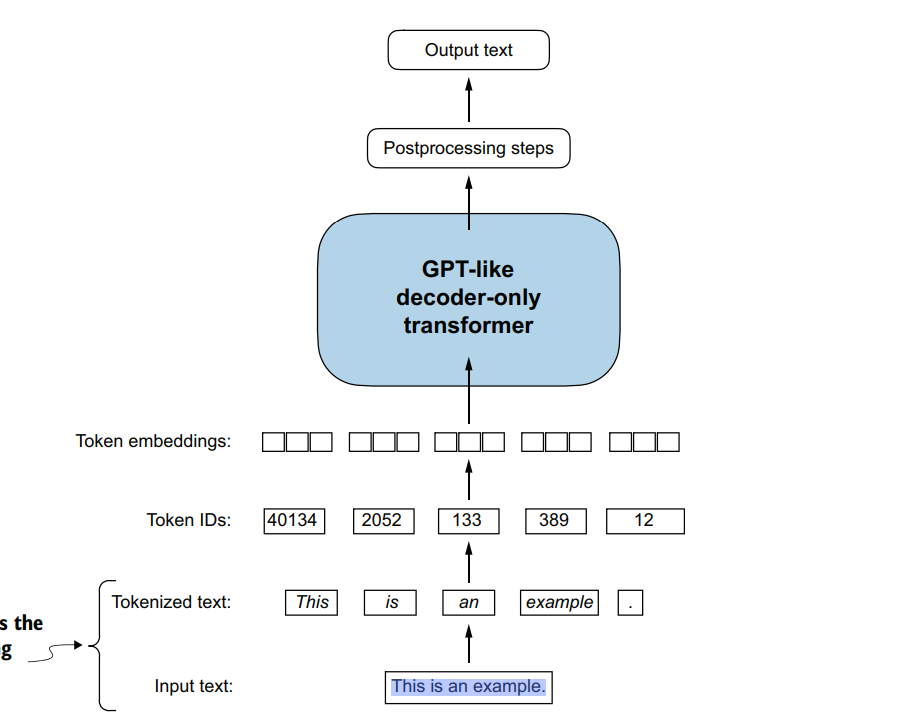

In [55]:
## in the llm that only understand the decoder only
## lets we start the basic ones:

In [56]:
import urllib.request
url = ("https://raw.githubusercontent.com/rasbt/"
 "LLMs-from-scratch/main/ch02/01_main-chapter-code/"
 "the-verdict.txt")
file_path = "the-verdict.txt"
urllib.request.urlretrieve(url, file_path)

('the-verdict.txt', <http.client.HTTPMessage at 0x7f660d9a9e00>)

In [57]:
with open("the-verdict.txt", "r", encoding="utf-8") as f:
 text = f.read()
print("Total number of character:", len(text))
print(text[:99])

Total number of character: 20479
I HAD always thought Jack Gisburn rather a cheap genius--though a good fellow enough--so it was no 


In [58]:
## lets we apply on the basic to undestand the tokenization.

In [59]:
import re
df = "my name is vivek and i love to read the history based book related to accient period"
# Using re.split to split the text into words by spaces
tokens = re.split(r'(\s)', df)
print(tokens)

['my', ' ', 'name', ' ', 'is', ' ', 'vivek', ' ', 'and', ' ', 'i', ' ', 'love', ' ', 'to', ' ', 'read', ' ', 'the', ' ', 'history', ' ', 'based', ' ', 'book', ' ', 'related', ' ', 'to', ' ', 'accient', ' ', 'period']


In [60]:
## lets we also remove the white space

In [61]:
result = re.split(r'([,.]|\s)', df)
print(result)

['my', ' ', 'name', ' ', 'is', ' ', 'vivek', ' ', 'and', ' ', 'i', ' ', 'love', ' ', 'to', ' ', 'read', ' ', 'the', ' ', 'history', ' ', 'based', ' ', 'book', ' ', 'related', ' ', 'to', ' ', 'accient', ' ', 'period']


In [62]:
## in the above the too many the white space in the sentence:

In [63]:
result = [item for item in result if item.strip()]
print(result)

['my', 'name', 'is', 'vivek', 'and', 'i', 'love', 'to', 'read', 'the', 'history', 'based', 'book', 'related', 'to', 'accient', 'period']


In [64]:
text1 = "Hello, world. Is this-- a test?"
result2 = re.split(r'([,.:;?_!"()\']|--|\s)',text1)
result2 = [item.strip() for item in result2 if item.strip()]
print(result2)

['Hello', ',', 'world', '.', 'Is', 'this', '--', 'a', 'test', '?']


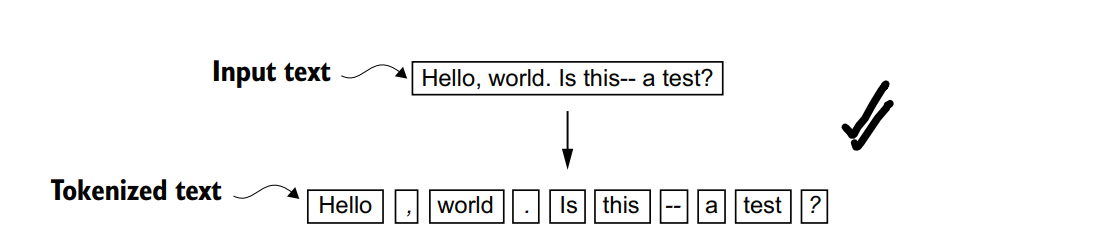

In [65]:
## now we split the the clean text into indivisul item:

In [66]:
##lets we apply on the raw text

In [67]:
clean_text = re.split(r'([,.:;?_!"()\']|--|\s)',text)
clean_text = [item.strip() for item in clean_text if item.strip()]
print(clean_text)

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in', 'the', 'height', 'of', 'his', 'glory', ',', 'he', 'had', 'dropped', 'his', 'painting', ',', 'married', 'a', 'rich', 'widow', ',', 'and', 'established', 'himself', 'in', 'a', 'villa', 'on', 'the', 'Riviera', '.', '(', 'Though', 'I', 'rather', 'thought', 'it', 'would', 'have', 'been', 'Rome', 'or', 'Florence', '.', ')', '"', 'The', 'height', 'of', 'his', 'glory', '"', '--', 'that', 'was', 'what', 'the', 'women', 'called', 'it', '.', 'I', 'can', 'hear', 'Mrs', '.', 'Gideon', 'Thwing', '--', 'his', 'last', 'Chicago', 'sitter', '--', 'deploring', 'his', 'unaccountable', 'abdication', '.', '"', 'Of', 'course', 'it', "'", 's', 'going', 'to', 'send', 'the', 'value', 'of', 'my', 'picture', "'", 'way', 'up', ';', 'but', 'I', 'don', "'", 't', 'think', 'of', 'that', ',

In [68]:
## lets we find out the length of the clean text

In [69]:
len(clean_text)

4690

In [70]:
print(clean_text[:30])

['I', 'HAD', 'always', 'thought', 'Jack', 'Gisburn', 'rather', 'a', 'cheap', 'genius', '--', 'though', 'a', 'good', 'fellow', 'enough', '--', 'so', 'it', 'was', 'no', 'great', 'surprise', 'to', 'me', 'to', 'hear', 'that', ',', 'in']


In [71]:
## and we do tokinization then we conver the token id :

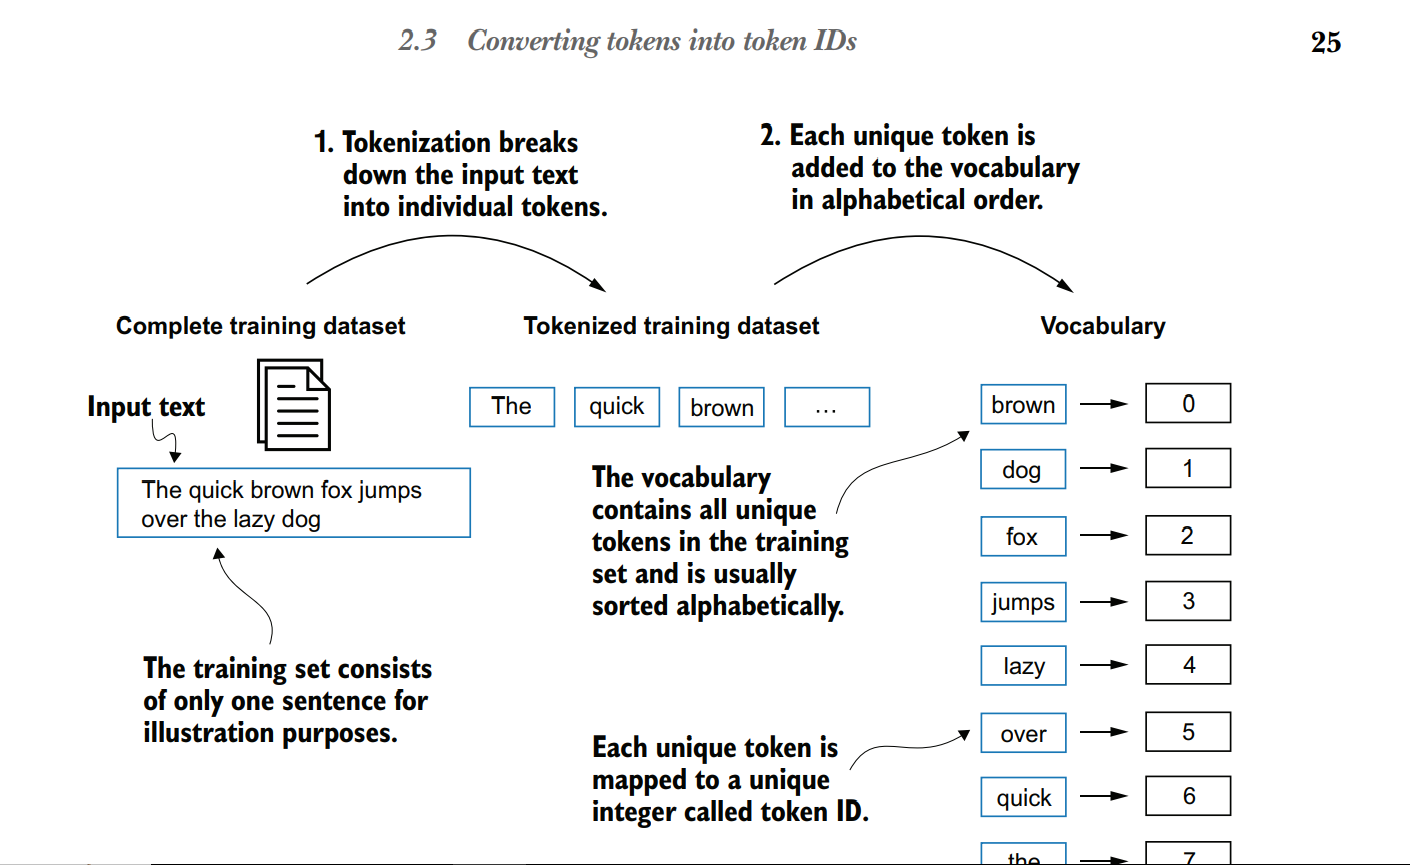

In [72]:
## to do the token id first we do the sort the all clean text
## then you can find the len of the all vocab
## then it will assigned it:


In [73]:
all_word = sorted(set(clean_text))

In [74]:
vocab_size = len(all_word)
print(vocab_size)

1130


In [75]:
vocab = {token:integer for integer,token in enumerate(all_word)}    ## Creating the vocabulary  # enumerate() provides two things for each element: its index and its value.
for i, item in enumerate(vocab.items()):   ## Loop through the vocabulary
 print(item)
 if i >= 50:
  break

('!', 0)
('"', 1)
("'", 2)
('(', 3)
(')', 4)
(',', 5)
('--', 6)
('.', 7)
(':', 8)
(';', 9)
('?', 10)
('A', 11)
('Ah', 12)
('Among', 13)
('And', 14)
('Are', 15)
('Arrt', 16)
('As', 17)
('At', 18)
('Be', 19)
('Begin', 20)
('Burlington', 21)
('But', 22)
('By', 23)
('Carlo', 24)
('Chicago', 25)
('Claude', 26)
('Come', 27)
('Croft', 28)
('Destroyed', 29)
('Devonshire', 30)
('Don', 31)
('Dubarry', 32)
('Emperors', 33)
('Florence', 34)
('For', 35)
('Gallery', 36)
('Gideon', 37)
('Gisburn', 38)
('Gisburns', 39)
('Grafton', 40)
('Greek', 41)
('Grindle', 42)
('Grindles', 43)
('HAD', 44)
('Had', 45)
('Hang', 46)
('Has', 47)
('He', 48)
('Her', 49)
('Hermia', 50)


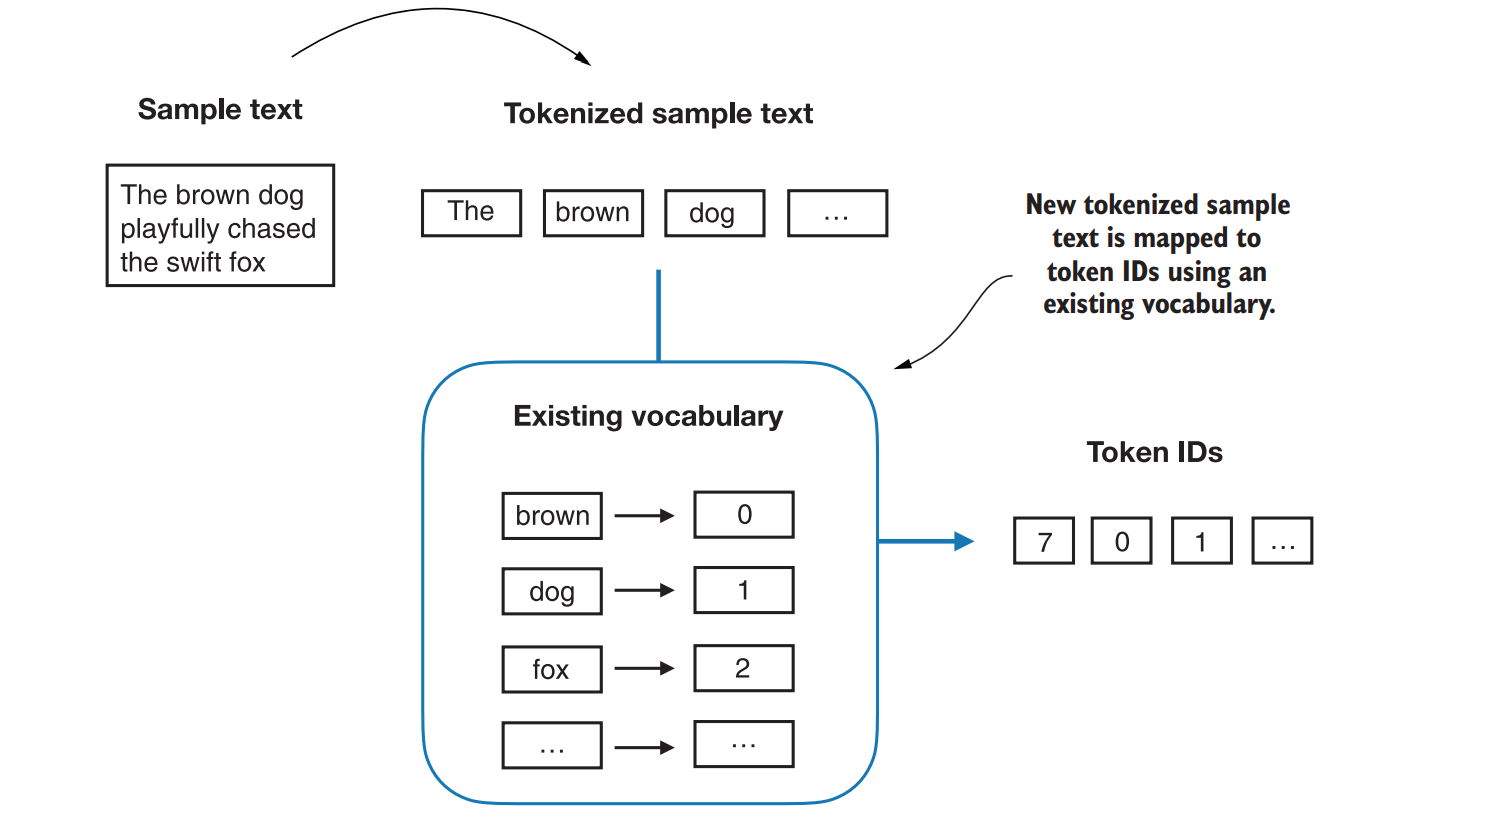

In [76]:
## lets we build the simple tokinizer

In [77]:
import re

# Redefining the class with the correct constructor __init__
class SimpleTokinizer:
  def __init__(self, vocab):
    self.str_to_int = vocab
    self.int_to_str = {i:s for s, i in vocab.items()}

  def encode(self, text):
    clean_text = re.split(r'([,.:;?_!"()\']|--|\s)', text)
    clean_text = [
        item.strip() for item in clean_text if item.strip()
    ]
    ids = [self.str_to_int[s] for s in clean_text]
    return ids

  def decode(self, ids):
    de_text = " ".join([self.int_to_str[i] for i in ids])
    de_text = re.sub(r'\s+([,.?!"()\'])', r'\1', de_text)
    return de_text

In [78]:
tokenizer = SimpleTokinizer(vocab)
text = """"It's the last he painted, you know,"
 Mrs. Gisburn said with pardonable pride."""
ids = tokenizer.encode(text)
print(ids)

[1, 56, 2, 850, 988, 602, 533, 746, 5, 1126, 596, 5, 1, 67, 7, 38, 851, 1108, 754, 793, 7]


In [79]:
## lets we do the constructor:

In [80]:
print(tokenizer.decode(ids))

" It' s the last he painted, you know," Mrs. Gisburn said with pardonable pride.


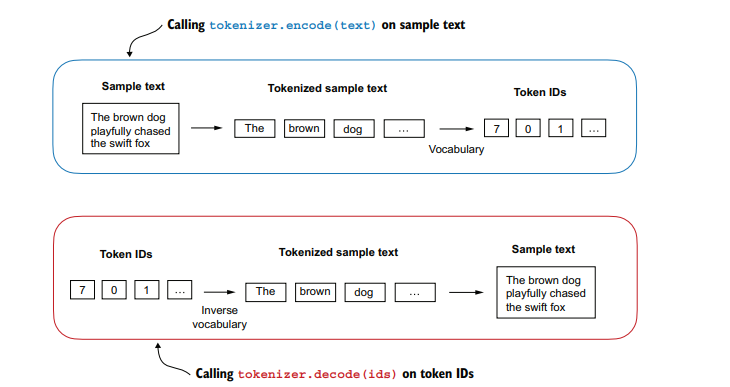

In [81]:
## lets we add the special contex token
## that able to handle the unknow word in the sentence

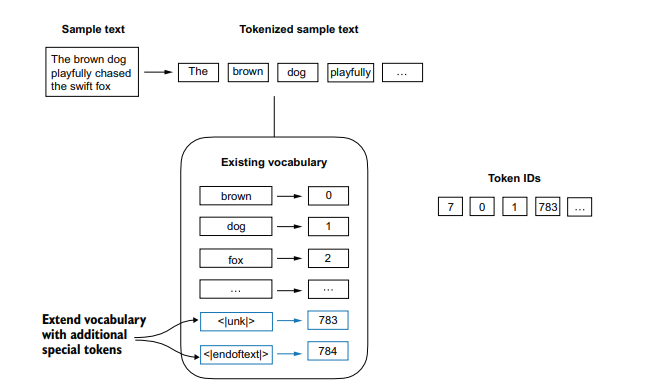

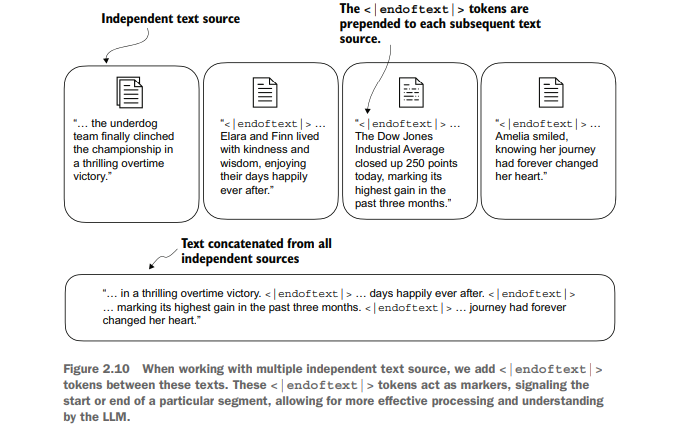

In [82]:
all_token = sorted(list(set(clean_text)))
all_token.extend(["<|endoftext|>", "<|unk|"])
vocab = {token:integer for integer,token in enumerate(all_token)}
print(len(vocab.items()))

1132


In [83]:
for i, item in enumerate(list(vocab.items())[-5:]):
  print(item)

('younger', 1127)
('your', 1128)
('yourself', 1129)
('<|endoftext|>', 1130)
('<|unk|', 1131)


In [84]:
## lets we implementation of the special token in the vocab

In [92]:

import re

class SimpleTokenizer:
    def __init__(self, vocab):
        self.str_to_int = vocab
        self.int_to_str = {i: s for s, i in vocab.items()}

    def encode(self, text):
        clean_text = re.split(
            r'([,.:;?_!"()\']|--|\s)', text
        )
        clean_text = [
            item.strip() for item in clean_text if item.strip()
        ]

        clean_text = [
            item if item in self.str_to_int else "<|unk|>"
            for item in clean_text
        ]

        ids = [self.str_to_int[s] for s in clean_text]
        return ids

    def decode(self, ids):
        de_text = " ".join(
            [self.int_to_str[i] for i in ids]
        )
        de_text = re.sub(
            r'\s+([,.?!"()\'])', r'\1', de_text
        )
        return de_text


In [93]:
## lets we do with the simple example of the sentence

In [97]:
text1 = "Hello, do you like tea?"
text2 = "In the sunlit terraces of the palace."
text = "<|endoftext|>".join((text1,text2))
print(text)

Hello, do you like tea?<|endoftext|>In the sunlit terraces of the palace.


In [98]:
## lets we apply on the whole on the simpletokinizer

In [99]:
tokinizer1 = SimpleTokinizer(vocab)
print(tokinizer1.encode(text))

[1131, 5, 355, 1126, 628, 975, 10, 1131, 988, 956, 984, 722, 988, 1131, 7]


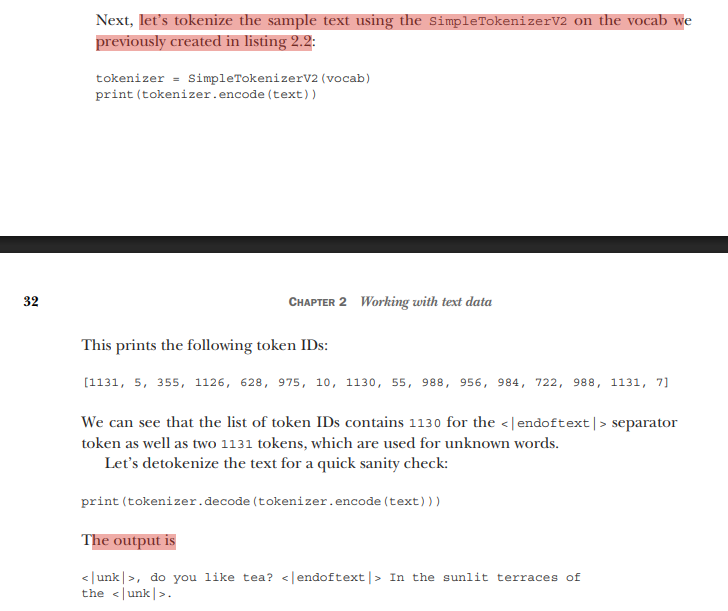

In [103]:
## that si the simple that use in the but in that
## chat gpt that is not use the simple method that is use
## the bye pair encoding method

In [104]:
## the byte pair that is so hard to code so it based on the
## version that called the **Tiktoken** that is the open liblary
## in the gpt2 and gpt3 model.

In [105]:
!pip install Tiktoken

In [108]:
from importlib.metadata import version
import tiktoken
print("tiktoken_version:", version("tiktoken"))

tiktoken_version: 0.14.0


In [109]:
## in that it directly converted the the sentence to encoding and decoding

In [110]:
tokenizer = tiktoken.get_encoding("gpt2")

In [113]:
text = (
 "Hello, do you like tea? <|endoftext|> In the sunlit terraces"
)
Integer = tokenizer.encode(text,allowed_special={"<|endoftext|>"})
print(Integer)

[15496, 11, 466, 345, 588, 8887, 30, 220, 50256, 554, 262, 4252, 18250, 8812, 2114]


In [114]:
string = tokenizer.decode(Integer)
print(string)

Hello, do you like tea? <|endoftext|> In the sunlit terraces


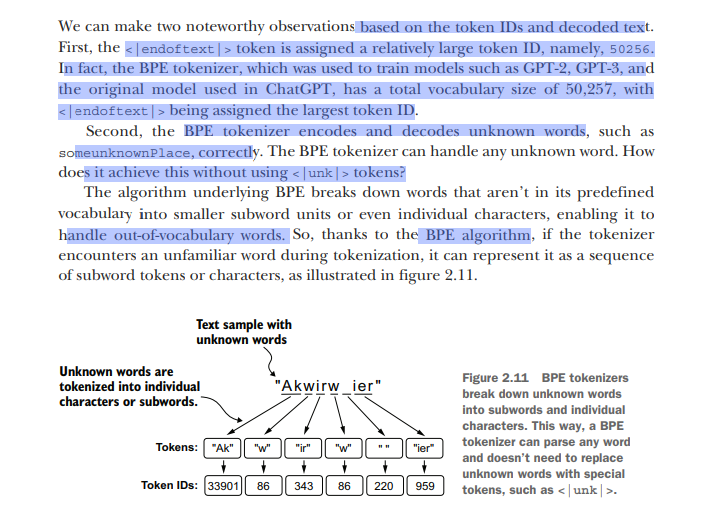